In [1]:
!pip install pytesseract opencv-python pillow

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 73.8/73.8 MB 32.3 MB/s  0:00:02


In [2]:
import cv2
import pytesseract
import numpy as np
import matplotlib.pyplot as plt

from PIL import Image
from google.colab import files

In [3]:
uploaded = files.upload()

Saving Screenshot 2026-11-12 191831.png to Screenshot 2026-11-12 191831 (1).png


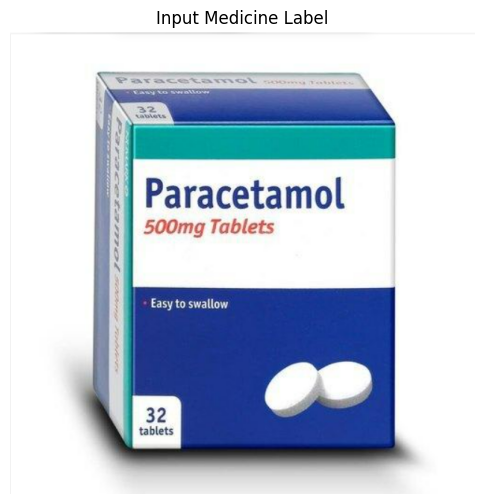

In [4]:
image_path = list(uploaded.keys())[0]

image = Image.open(image_path)

plt.figure(figsize=(10, 6))
plt.imshow(image)
plt.axis("off")
plt.title("Input Medicine Label")
plt.show()

In [5]:
img = cv2.imread(image_path)

print("Image loaded successfully.")
print("Image shape:", img.shape)

Image loaded successfully.
Image shape: (619, 623, 3)


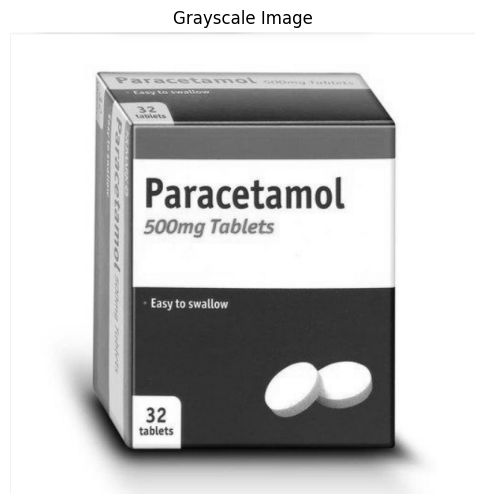

In [6]:
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

plt.figure(figsize=(10, 6))
plt.imshow(gray, cmap="gray")
plt.axis("off")
plt.title("Grayscale Image")
plt.show()

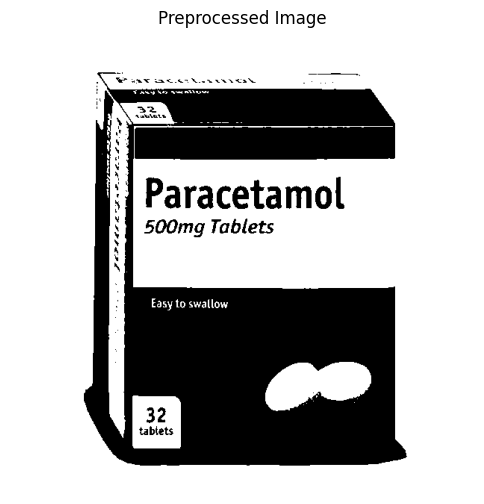

In [7]:
_, threshold = cv2.threshold(
    gray,
    0,
    255,
    cv2.THRESH_BINARY + cv2.THRESH_OTSU
)

plt.figure(figsize=(10, 6))
plt.imshow(threshold, cmap="gray")
plt.axis("off")
plt.title("Preprocessed Image")
plt.show()

In [8]:
text = pytesseract.image_to_string(threshold)

print("Extracted Text:")
print("----------------")
print(text)

Extracted Text:
----------------
: Paracetamol

500mg Tablets

Easy to swallow

tablets




In [9]:
clean_text = text.strip()

print("MEDICINE LABEL INFORMATION")
print("===========================")
print(clean_text)

MEDICINE LABEL INFORMATION
: Paracetamol

500mg Tablets

Easy to swallow

tablets


In [10]:
import re

lines = [line.strip() for line in clean_text.split("\n") if line.strip()]

print("Important extracted information:")
print()

for line in lines:
    print("-", line)

Important extracted information:

- : Paracetamol
- 500mg Tablets
- Easy to swallow
- tablets


In [11]:
dosage_pattern = r'\b\d+\s*(mg|g|ml|mcg|%|iu)\b'

dosages = re.findall(
    dosage_pattern,
    clean_text,
    flags=re.IGNORECASE
)

if dosages:
    print("Possible dosage information found:")
    for dosage in dosages:
        print("-", dosage)
else:
    print("No dosage information detected.")

Possible dosage information found:
- mg


In [12]:
expiry_keywords = ["exp", "expiry", "expires", "use before"]

print("Expiry-related information:")

found = False

for line in lines:
    if any(word in line.lower() for word in expiry_keywords):
        print("-", line)
        found = True

if not found:
    print("No clear expiry information detected.")

Expiry-related information:
No clear expiry information detected.


In [1]:

!pip install opencv-contrib-python-headless

In [2]:
import cv2
import pytesseract
import numpy as np
import matplotlib.pyplot as plt

from PIL import Image
from google.colab import files

In [3]:
import cv2

print("OpenCV version:", cv2.__version__)
print("CascadeClassifier available:", hasattr(cv2, "CascadeClassifier"))

OpenCV version: 5.0.0
CascadeClassifier available: True


In [4]:
from deepface import DeepFace

print("DeepFace imported successfully!")

DeepFace imported successfully!


In [5]:
from google.colab import files

uploaded_face = files.upload()

Saving Screenshot 2026-11-11 215519.png to Screenshot 2026-11-11 215519.png


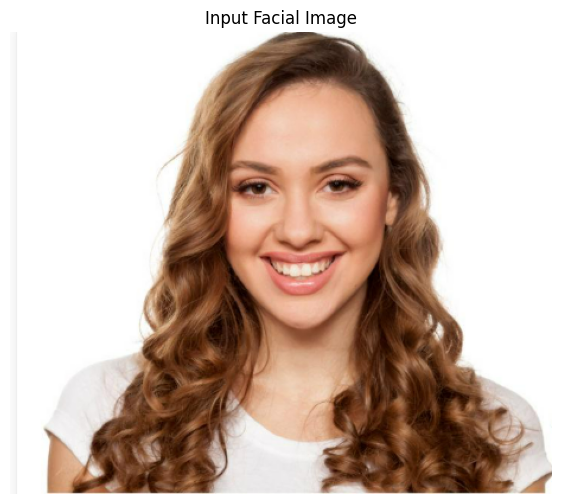

In [6]:
face_path = list(uploaded_face.keys())[0]

face_image = Image.open(face_path)

plt.figure(figsize=(8, 6))
plt.imshow(face_image)
plt.axis("off")
plt.title("Input Facial Image")
plt.show()

In [7]:
result = DeepFace.analyze(
    img_path=face_path,
    actions=["emotion"],
    enforce_detection=False
)

print(result)

26-11-12 14:04:26 - 🔗 haarcascade_frontalface_default.xml will be downloaded from https://github.com/opencv/opencv/raw/4.9.0/data/haarcascades/haarcascade_frontalface_default.xml to /root/.deepface/weights/haarcascade_frontalface_default.xml...


Downloading...
From: https://github.com/opencv/opencv/raw/4.9.0/data/haarcascades/haarcascade_frontalface_default.xml
To: /root/.deepface/weights/haarcascade_frontalface_default.xml
930kB [00:00, 43.1MB/s]                   


26-11-12 14:04:27 - 🔗 haarcascade_eye.xml will be downloaded from https://github.com/opencv/opencv/raw/4.9.0/data/haarcascades/haarcascade_eye.xml to /root/.deepface/weights/haarcascade_eye.xml...


Downloading...
From: https://github.com/opencv/opencv/raw/4.9.0/data/haarcascades/haarcascade_eye.xml
To: /root/.deepface/weights/haarcascade_eye.xml
341kB [00:00, 34.2MB/s]                    


26-11-12 14:04:28 - 🔗 facial_expression_model_weights.h5 will be downloaded from https://github.com/serengil/deepface_models/releases/download/v1.0/facial_expression_model_weights.h5 to /root/.deepface/weights/facial_expression_model_weights.h5...


Downloading...
From: https://github.com/serengil/deepface_models/releases/download/v1.0/facial_expression_model_weights.h5
To: /root/.deepface/weights/facial_expression_model_weights.h5
100%|██████████| 5.98M/5.98M [00:00<00:00, 75.7MB/s]


[{'emotion': {'angry': np.float32(1.3961087e-11), 'disgust': np.float32(2.8177243e-17), 'fear': np.float32(7.6444506e-10), 'happy': np.float32(99.92155), 'sad': np.float32(7.933681e-08), 'surprise': np.float32(2.6791195e-05), 'neutral': np.float32(0.078433126)}, 'dominant_emotion': 'happy', 'region': {'x': 156, 'y': 61, 'w': 175, 'h': 175, 'left_eye': (276, 129), 'right_eye': (206, 131)}, 'face_confidence': 0.91}]


In [8]:
# Extract the emotion result

if isinstance(result, list):
    emotion_data = result[0]
else:
    emotion_data = result

dominant_emotion = emotion_data["dominant_emotion"]

print("Detected Emotion:", dominant_emotion)

Detected Emotion: happy


In [9]:
# Display emotion confidence scores

emotion_scores = emotion_data["emotion"]

print("Emotion Scores")
print("========================")

for emotion, score in emotion_scores.items():
    print(f"{emotion}: {score:.2f}%")

Emotion Scores
angry: 0.00%
disgust: 0.00%
fear: 0.00%
happy: 99.92%
sad: 0.00%
surprise: 0.00%
neutral: 0.08%


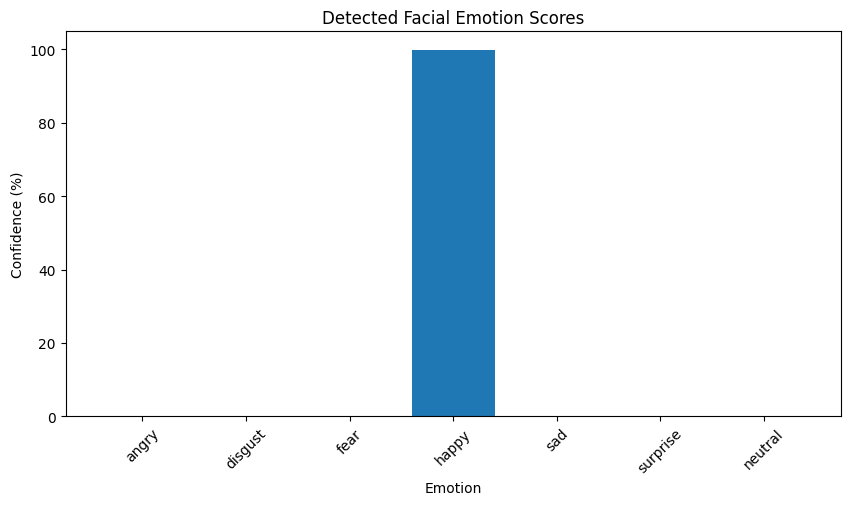

In [10]:
# Visualize emotion scores

plt.figure(figsize=(10, 5))

plt.bar(
    emotion_scores.keys(),
    emotion_scores.values()
)

plt.xlabel("Emotion")
plt.ylabel("Confidence (%)")
plt.title("Detected Facial Emotion Scores")
plt.xticks(rotation=45)
plt.show()

In [11]:
# Generate a cognitive response based on detected emotion

responses = {
    "happy": "You appear to be in a positive mood. Keep enjoying the moment!",

    "sad": "You may appear to be feeling sad. Taking some time for yourself or talking to someone you trust may help.",

    "angry": "You may appear to be feeling angry. Taking a short pause and breathing calmly may help.",

    "fear": "You may appear worried or afraid. Try to stay calm and focus on what makes you feel safe.",

    "surprise": "You appear surprised. Something unexpected may have caught your attention.",

    "disgust": "Your facial expression may indicate discomfort or dislike.",

    "neutral": "Your facial expression appears neutral."
}

response = responses.get(
    dominant_emotion.lower(),
    "The system could not interpret the detected emotion clearly."
)

print("==============================================")
print("       EMOTION-AWARE COGNITIVE ASSISTANT")
print("==============================================")

print("\nDetected Emotion:")
print(dominant_emotion)

print("\nAssistant Response:")
print(response)

       EMOTION-AWARE COGNITIVE ASSISTANT

Detected Emotion:
happy

Assistant Response:
You appear to be in a positive mood. Keep enjoying the moment!


In [12]:
from google.colab import files

uploaded = files.upload()

Saving Screenshot 2026-11-11 215707.png to Screenshot 2026-11-11 215707.png


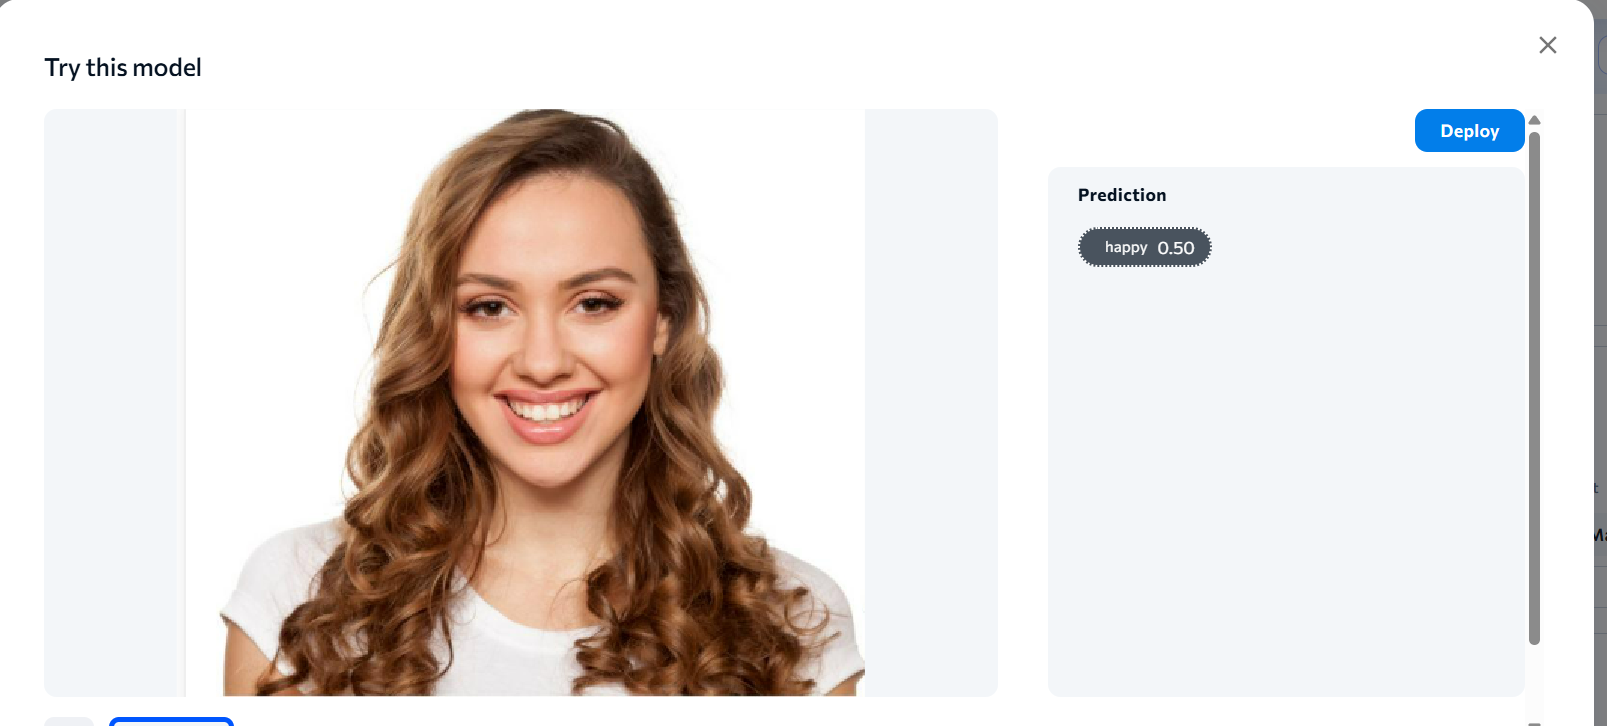

In [13]:
from IPython.display import Image, display

display(Image(filename=list(uploaded.keys())[0]))

In [14]:
from google.colab import files

uploaded = files.upload()

Saving Screenshot 2026-11-12 194502.png to Screenshot 2026-11-12 194502.png


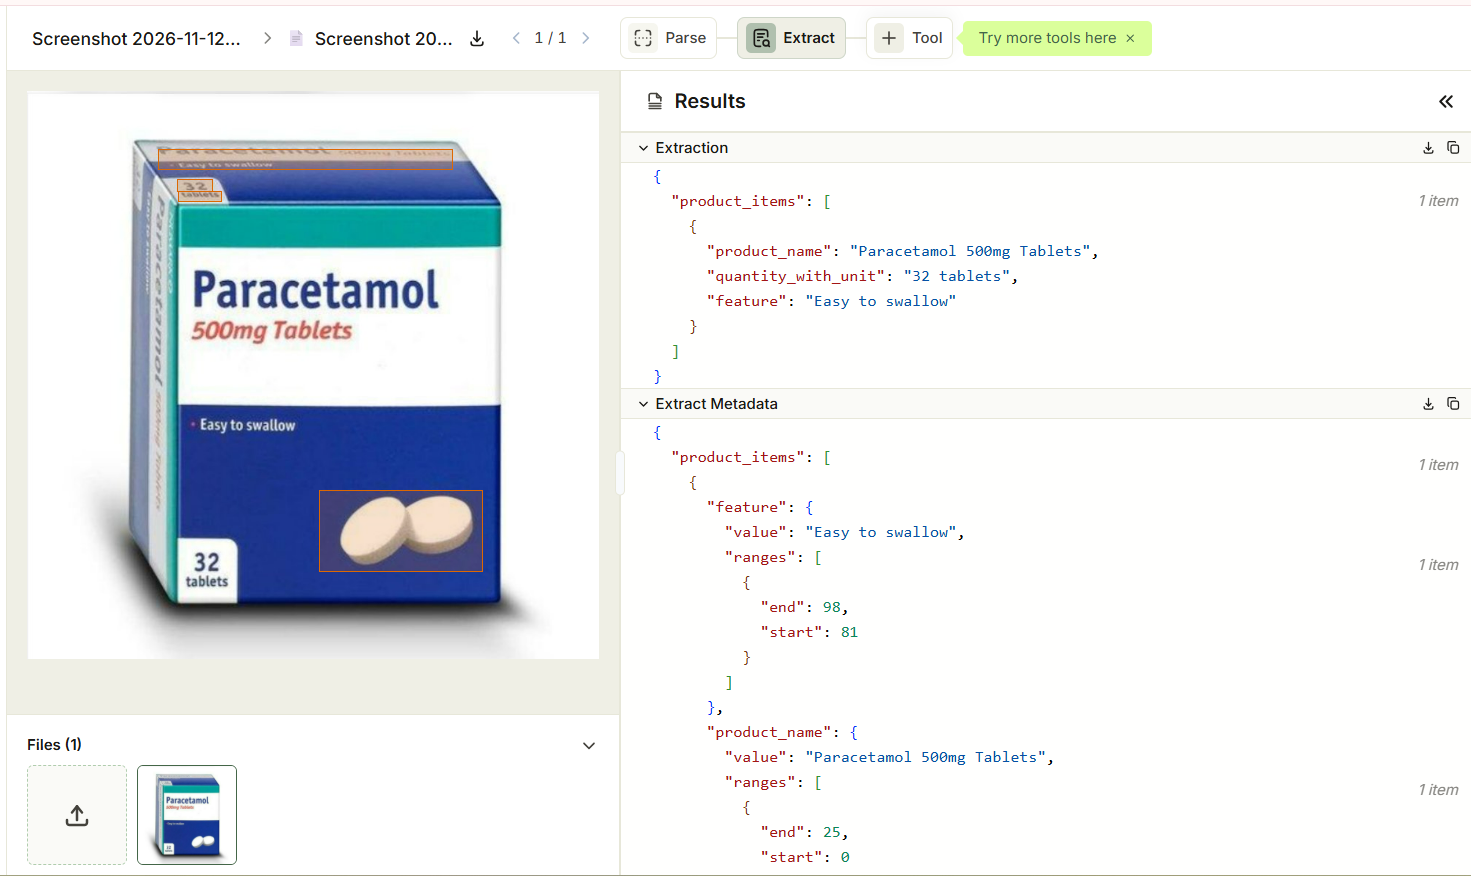

In [15]:
from IPython.display import Image, display

display(Image(filename=list(uploaded.keys())[0]))